In [1]:
!pip install pandas numpy matplotlib wordcloud

In [6]:
import pandas as pd
from google.colab import files

# Upload CSV file
uploaded = files.upload()

# Get uploaded filename
file_name = list(uploaded.keys())[0]

# Read CSV with alternative encoding
df = pd.read_csv(file_name, encoding='ISO-8859-1')

# Display first five records
display(df.head())

# Display dataset information
df.info()

Saving Dataset-SA.csv.zip to Dataset-SA.csv.zip


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205052 entries, 0 to 205051
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   product_name   205052 non-null  object
 1   product_price  205052 non-null  object
 2   Rate           205052 non-null  object
 3   Review         180388 non-null  object
 4   Summary        205041 non-null  object
 5   Sentiment      205052 non-null  object
dtypes: object(6)
memory usage: 9.4+ MB


In [7]:
# Automatically identify required columns

def find_column(dataframe, candidates):
    for candidate in candidates:
        for col in dataframe.columns:
            if col.strip().lower() == candidate.lower():
                return col
    return None

product_col = find_column(
    df, ['product_name', 'product name', 'product', 'name']
)

rating_col = find_column(
    df, ['Rate', 'rating', 'ratings', 'product_rating']
)

price_col = find_column(
    df, ['price', 'product_price', 'discounted_price',
         'discounted price', 'selling_price']
)

summary_col = find_column(
    df, ['Summary', 'summary', 'review_summary']
)

# Check identified columns
print("Product column:", product_col)
print("Rating column:", rating_col)
print("Price column:", price_col)
print("Summary column:", summary_col)

# Check whether required columns exist
if None in [product_col, rating_col, price_col, summary_col]:
    raise ValueError(
        "Required columns not found. Check the dataset column names "
        "and update the column candidates."
    )

# Clean rating field
df[rating_col] = pd.to_numeric(
    df[rating_col].astype(str).str.extract(r'(\d+\.?\d*)')[0],
    errors='coerce'
)

# Clean price field
df[price_col] = pd.to_numeric(
    df[price_col].astype(str)
    .str.replace(',', '', regex=False)
    .str.extract(r'(\d+\.?\d*)')[0],
    errors='coerce'
)

# Remove records with missing essential values
df = df.dropna(
    subset=[product_col, rating_col, price_col]
).copy()

# Clean product names and summary text
df[product_col] = df[product_col].astype(str).str.strip()

df[summary_col] = df[summary_col].fillna('').astype(str)

# Display cleaned data
print("Cleaned dataset:")
display(df.head())

print("Total records after cleaning:", len(df))

Product column: product_name
Rating column: Rate
Price column: product_price
Summary column: Summary
Cleaned dataset:


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5.0,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5.0,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3.0,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1.0,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3.0,fair,ok ok product,neutral


Total records after cleaning: 205052


In [8]:
# Group by product name and calculate mean values

items = df.groupby(product_col).agg(
    mean_rating=(rating_col, 'mean'),
    mean_price=(price_col, 'mean')
).reset_index()

# Round values to two decimal places
items['mean_rating'] = items['mean_rating'].round(2)
items['mean_price'] = items['mean_price'].round(2)

# Display summary DataFrame
print("Product-wise Statistical Summary:")
display(items.head(10))

# Display total number of products
print("Total unique products:", len(items))

Product-wise Statistical Summary:


,product_name,mean_rating,mean_price
0,1170BLBR Unique New Day Date Analog Watch F...,3.99,299.0
1,288SDTL TIMEWEAR Silver Pink Dial Stainless St...,4.41,339.0
2,38024PP25 Minimalists Analog Watch For Men,4.89,850.0
3,3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...,3.67,417.0
4,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...,4.75,199.0
5,77085PP03 Volt Analog Watch For Men,4.71,699.0
6,7SEVEN Airtel DTH Remote Airtel Xstream Remote...,4.69,219.0
7,"ADONYX Combo of Knee,Palm, Elbow & Ankle Support",3.80,199.0
8,ADZOY Metal Lazy Stand Bracket for Neck Rest o...,3.52,284.0
9,AGAMI Green 2 Layer Lucky Bamboo plant with Bi...,4.46,279.0


Total unique products: 958


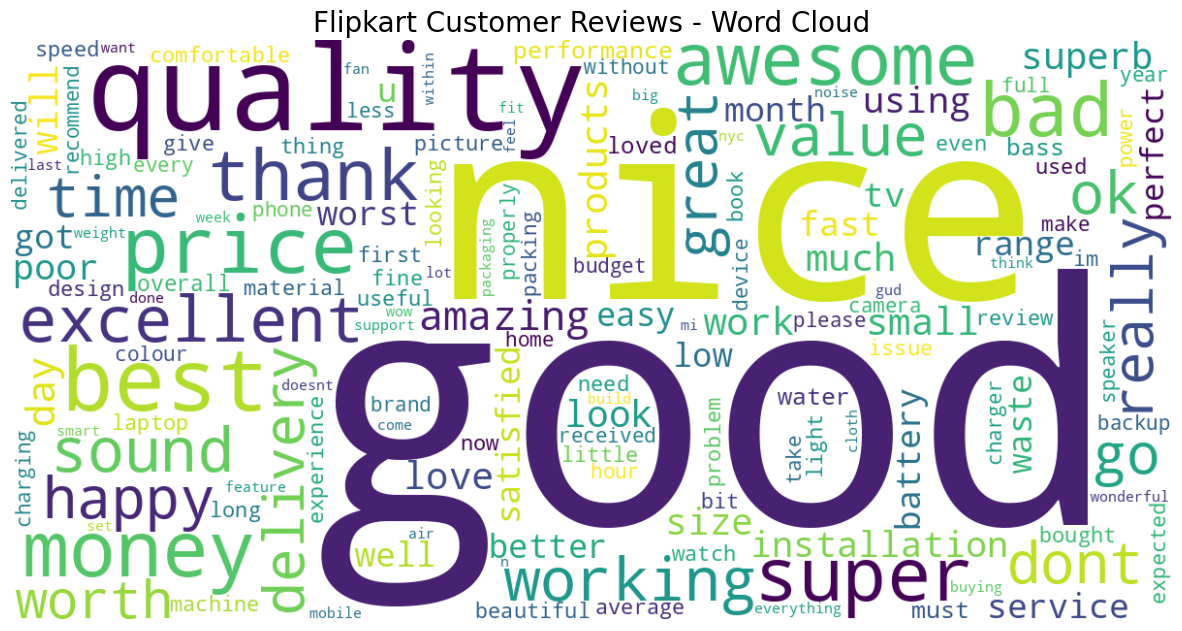

Word Cloud generated and saved successfully!


In [9]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

# Combine all customer summaries into one text
text = " ".join(
    df[summary_col].dropna().astype(str)
)

# Define common words to exclude
stopwords = set(STOPWORDS)

stopwords.update([
    'product', 'flipkart', 'item', 'buy',
    'purchase', 'use', 'one', 'also'
])

# Generate Word Cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    stopwords=stopwords,
    max_words=150,
    collocations=False,
    contour_width=1
).generate(text)

# Display Word Cloud
plt.figure(figsize=(15, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')

plt.title(
    'Flipkart Customer Reviews - Word Cloud',
    fontsize=20
)

plt.show()

# Save Word Cloud image
wordcloud.to_file('flipkart_wordcloud.png')

print("Word Cloud generated and saved successfully!")

In [10]:
# Export product-wise summary
items.to_excel(
    'Flipkart_Product_Summary.xlsx',
    index=False
)

print("Excel file exported successfully!")

Excel file exported successfully!


In [11]:
# Export product-wise summary
items.to_excel(
    'Flipkart_Product_Summary.xlsx',
    index=False
)

print("Excel file exported successfully!")

Excel file exported successfully!
